# 对齐feature：移除progress输入的传统模型比较

新10＋17列输入。5种学习器分别none/balanced，另有Dummy参照，共11个模型。
**Run All只读保存结果，不训练。** 数据为回顾性百分比采样，包含终局，历史测试已查看。
方法见[说明](docs/PROGRESSIVE_BASELINES_ZH.md)，完整表见[报告](modelling_baselines/run_20261026_feature_01/RESULTS_ZH.md)。

In [1]:
import pandas as pd
from IPython.display import display, Image
from src.progressive_baselines import project_root, DEFAULT_OUTPUT
root = project_root()
run = root / DEFAULT_OUTPUT
metrics = pd.read_csv(run / "tables/metrics.csv")
pooled = metrics[metrics["split"].eq("test") & metrics.checkpoint.eq("all")]
columns = ["family", "weighting", "accuracy", "macro_f1", "draw_precision", "draw_recall", "draw_f1", "log_loss", "macro_auc"]
print("Same 27 inputs; retrospective test snapshots; no progress input.")

Same 27 inputs; retrospective test snapshots; no progress input.


## 不加权与balanced分别报告

Dummy以训练经验先验作参照，balanced不适用。GaussianNB用训练sample_weight，其他学习器用class_weight。

,family,weighting,accuracy,macro_f1,draw_precision,draw_recall,draw_f1,log_loss,macro_auc
6,dummy,none,0.4986,0.2218,0.0000,0.0000,0.0000,0.8486,0.5000
18,logistic,none,0.6923,0.4716,0.0000,0.0000,0.0000,0.6814,0.7350
42,gaussian_nb,none,0.6675,0.4913,0.0964,0.0799,0.0874,1.3270,0.7182
66,decision_tree,none,0.6790,0.4620,0.0000,0.0000,0.0000,0.7308,0.6818
90,random_forest,none,0.6906,0.4703,0.0000,0.0000,0.0000,0.6841,0.7392
114,gradient_boosting,none,0.6923,0.4737,0.1333,0.0030,0.0059,0.6764,0.7566


,family,weighting,accuracy,macro_f1,draw_precision,draw_recall,draw_f1,log_loss,macro_auc
30,logistic,balanced,0.5621,0.4661,0.0589,0.3439,0.1005,0.9170,0.7330
54,gaussian_nb,balanced,0.5128,0.4426,0.0578,0.4268,0.1019,1.6227,0.7112
78,decision_tree,balanced,0.4639,0.4058,0.0534,0.4766,0.0960,0.9733,0.6849
102,random_forest,balanced,0.5625,0.4675,0.0582,0.3454,0.0996,0.8959,0.7347
126,gradient_boosting,balanced,0.6013,0.4886,0.0852,0.3544,0.1374,0.8675,0.7483


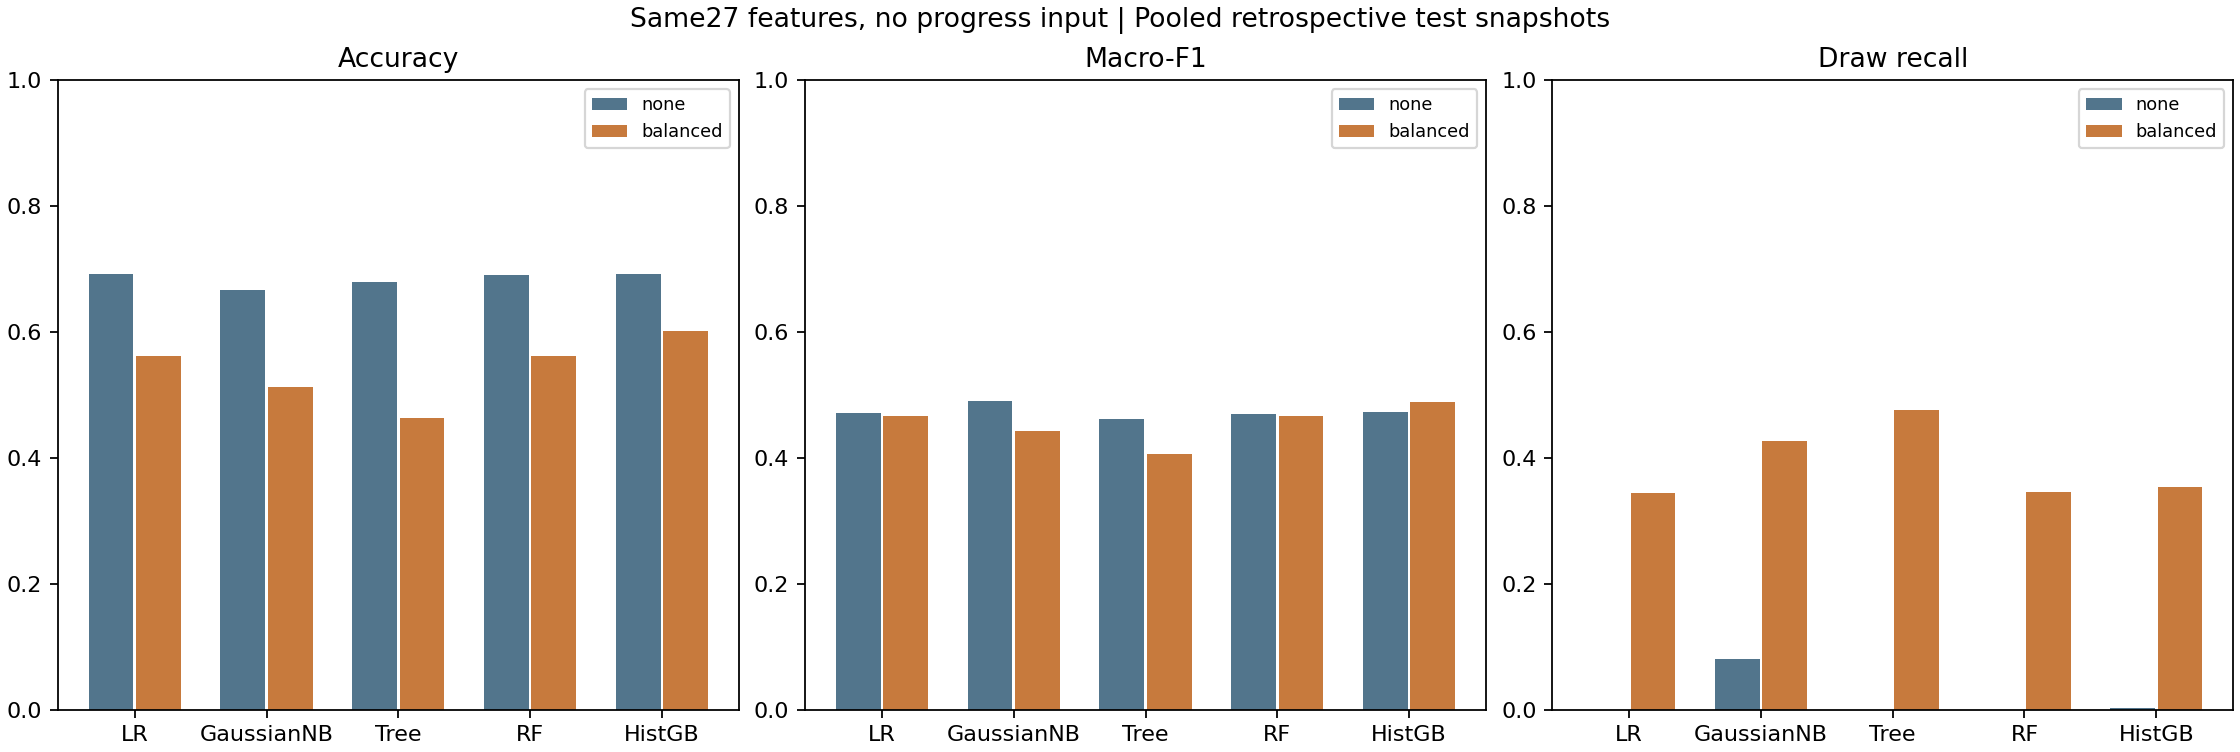

In [2]:
display(pooled[pooled.weighting.eq("none")][columns].round(4))
display(pooled[pooled.weighting.eq("balanced")][columns].round(4))
display(Image(filename=str(run / "figures/weights.png")))

## 每个观察时点

百分比取自最终棋谱长度；10%不是固定10步，100%是最后记录局面。

In [3]:
display(metrics[metrics["split"].eq("test") & metrics.checkpoint.ne("all")][
    ["family", "weighting", "checkpoint", "n", "accuracy", "macro_f1", "draw_precision", "draw_recall", "draw_f1"]].round(4))

,family,weighting,checkpoint,n,accuracy,macro_f1,draw_precision,draw_recall,draw_f1
7,dummy,none,0.1,2803,0.4973,0.2214,0.0000,0.0000,0.0000
8,dummy,none,0.25,2830,0.4986,0.2218,0.0000,0.0000,0.0000
9,dummy,none,0.5,2849,0.4988,0.2219,0.0000,0.0000,0.0000
10,dummy,none,0.75,2830,0.4986,0.2218,0.0000,0.0000,0.0000
11,dummy,none,1.0,2867,0.4995,0.2221,0.0000,0.0000,0.0000
19,logistic,none,0.1,2803,0.6061,0.4112,0.0000,0.0000,0.0000
20,logistic,none,0.25,2830,0.6244,0.4241,0.0000,0.0000,0.0000
21,logistic,none,0.5,2849,0.6392,0.4351,0.0000,0.0000,0.0000
22,logistic,none,0.75,2830,0.7219,0.4925,0.0000,0.0000,0.0000
23,logistic,none,1.0,2867,0.8671,0.5916,0.0000,0.0000,0.0000


## 分类别表现与参数

训练来源、完整参数、逐局面概率和三分类混淆矩阵都在结果目录；验证及测试完整数值保存在metrics.csv。

In [4]:
import json
display(pd.read_csv(run / "tables/per_class.csv").round(4))
print(json.loads((run / "artifacts/train_class_weights.json").read_text(encoding="utf-8")))
verification = json.loads((run / "artifacts/verification.json").read_text(encoding="utf-8"))
print("Saved verification:", verification["status"], verification["check_count"])
print("Reload check: python verify_progressive_baselines.py --reload-models")

,slug,split,label,precision,recall,f1-score,support
0,dummy_none,validation,black,0.0000,0.0000,0.0000,6450.0
1,dummy_none,validation,draw,0.0000,0.0000,0.0000,660.0
2,dummy_none,validation,white,0.4993,1.0000,0.6660,7090.0
3,dummy_none,test,black,0.0000,0.0000,0.0000,6447.0
4,dummy_none,test,draw,0.0000,0.0000,0.0000,663.0
...,...,...,...,...,...,...,...
61,hgb_balanced,validation,draw,0.0721,0.3106,0.1171,660.0
62,hgb_balanced,validation,white,0.7316,0.6267,0.6751,7090.0
63,hgb_balanced,test,black,0.7098,0.5969,0.6485,6447.0
64,hgb_balanced,test,draw,0.0852,0.3544,0.1374,663.0


{'counts': [30129, 3088, 33129], 'class_weights': [0.7340214853905982, 7.161701208981002, 0.6675520943382938], 'effective_balanced_counts': [22115.333333325147, 22115.333333333205, 22115.333333347586]}
Saved verification: passed 1728
Reload check: python verify_progressive_baselines.py --reload-models
